# 🍄 Taller de Clustering — Parte 1: Setas

Notebook de trabajo: solo contiene las fases ya vistas (ver [`learn_roadmap.md`](learn_roadmap.md)).

## ✅ Fase 01 · Comprensión del problema y de los datos — ya vista

> **Resumen fase 01:** 8124 setas × 23 columnas, **todas categóricas** (letras). Hay etiqueta (`class`), pero solo para validar. No hay nulos *aparentes*.

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

In [1]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook
import warnings
warnings.filterwarnings("ignore")  # oculta avisos para que la salida quede limpia

import pandas as pd              # DataFrame: la "hoja de cálculo" con la que trabajamos
import numpy as np               # cálculo numérico
import seaborn as sns            # gráficos estadísticos con poco código
import matplotlib.pyplot as plt  # base de todos los gráficos

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # semilla fija: así los resultados se pueden repetir

df = pd.read_csv("docs/workshop/data/mushrooms.csv")  # la tabla con todas las setas
print("Filas x columnas:", df.shape)
df.head()  # las 5 primeras filas

# Con texto, describe() da: count (filas), unique (valores distintos),
# top (el más repetido) y freq (cuántas veces sale).
df.describe()

# Tipo de cada columna: todas salen 'str' (texto; en pandas antiguos sale 'object').
# Cada letra es un código, p. ej. en 'class': e = comestible, p = venenosa.
df.info()

# ¿Cuántas setas de cada clase? (solo para conocer los datos, no para agrupar)
df["class"].value_counts()

# Contar nulos por columna. Sale todo 0... pero ojo: los valores desconocidos
# pueden estar escritos como '?' (lo veremos en la fase 02).
df.isnull().sum()

Filas x columnas: (8124, 23)
<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

## ✅ Fase 02 · Preparación de los datos — ya vista

> **Resumen fase 02:** `'?'` → moda en `stalk-root`, fuera `veil-type`, etiqueta separada en `y` y **One-Hot** para pasar de 22 columnas de letras a columnas 0/1.

▶️ **Ejecuta primero la celda plegada de abajo** (o usa *Run All*): crea `df`, `X`, `y`… que necesita la fase actual. Pulsa `…` para ver su código.

In [2]:
n_values = pd.DataFrame({
    "feature": df.columns,                                  # nombre de cada columna
    "n_values": [df[col].nunique() for col in df.columns],  # cuántos valores distintos tiene
})
n_values.sort_values("n_values").head()  # de menos a más: lo raro sale arriba

# Imprimimos los valores distintos de cada columna, ordenados.
# Buscamos a ojo algo que no sea una letra-código: '?', '-', 'NA', ''...
for col in df.columns:
    print(f"{col:26} {sorted(df[col].unique())}")

# Lo confirmamos contando: ¿cuántos '?' hay en cada columna? Nos quedamos con las que tengan alguno.
interrogantes = (df == "?").sum()
interrogantes[interrogantes > 0]

# Ya sabemos dónde mirar: ¿cuánto pesa el '?' dentro de 'stalk-root'?
df["stalk-root"].value_counts()

# La moda es el valor más repetido. La calculamos SIN contar los '?'.
moda = df.loc[df["stalk-root"] != "?", "stalk-root"].mode()[0]
print("Moda de stalk-root:", moda)

df["stalk-root"] = df["stalk-root"].replace("?", moda)  # cambiamos cada '?' por la moda
df["stalk-root"].value_counts()

# Columnas con un solo valor: son iguales en todas las setas, no ayudan a distinguir nada
constantes = [col for col in df.columns if df[col].nunique() == 1]
print("Eliminamos:", constantes)
df = df.drop(columns=constantes)
df.shape

y = (df["class"] == "p").astype(int)  # 1 = venenosa, 0 = comestible (solo para validar)
X = df.drop(columns="class")          # las características de la seta
X.shape, y.value_counts().to_dict()

X = pd.get_dummies(X, dtype=int)  # una columna 0/1 por cada valor posible
print("Columnas tras One-Hot:", X.shape[1])
X.iloc[:3, :8]  # vistazo a las primeras columnas

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=RANDOM_STATE)
X_train.shape, X_test.shape

class                      ['e', 'p']
cap-shape                  ['b', 'c', 'f', 'k', 's', 'x']
cap-surface                ['f', 'g', 's', 'y']
cap-color                  ['b', 'c', 'e', 'g', 'n', 'p', 'r', 'u', 'w', 'y']
bruises                    ['f', 't']
odor                       ['a', 'c', 'f', 'l', 'm', 'n', 'p', 's', 'y']
gill-attachment            ['a', 'f']
gill-spacing               ['c', 'w']
gill-size                  ['b', 'n']
gill-color                 ['b', 'e', 'g', 'h', 'k', 'n', 'o', 'p', 'r', 'u', 'w', 'y']
stalk-shape                ['e', 't']
stalk-root                 ['?', 'b', 'c', 'e', 'r']
stalk-surface-above-ring   ['f', 'k', 's', 'y']
stalk-surface-below-ring   ['f', 'k', 's', 'y']
stalk-color-above-ring     ['b', 'c', 'e', 'g', 'n', 'o', 'p', 'w', 'y']
stalk-color-below-ring     ['b', 'c', 'e', 'g', 'n', 'o', 'p', 'w', 'y']
veil-type                  ['p']
veil-color                 ['n', 'o', 'w', 'y']
ring-number                ['n', 'o', 't']
ring-typ

((5443, 115), (2681, 115))

## Fase 03 · Exploración y reducción de dimensionalidad

**Objetivo:** *ver* los datos (115 columnas no se pueden dibujar) y medir cuánta información tienen.

### PCA: de 115 columnas a 2 para poder dibujar

**Qué es:** una forma de **resumir muchas columnas en pocas sin perder lo importante**. Busca los **ejes (direcciones) en los que los datos más se diferencian**: si una columna vale lo mismo en todas las setas, no ayuda a distinguirlas.

- **PC1** = el eje con más diferencias; **PC2** = el segundo. Cada seta pasa a ser un punto (PC1, PC2).
- *Analogía:* resumir las 13 notas de un estudiante en 2 números que lo describen bien.
- Normalmente **primero se escala**; con las setas **no hace falta**: tras el One-Hot todo vale 0 o 1.

![PCA: qué es](assets/taller/f03-pca-que-es.png)

![Pasos del PCA](assets/taller/f03-pca-pasos.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En los libros**
>
> - **Primer libro:** comprime los dígitos manuscritos de **MNIST** de **784 píxeles a 154 componentes** guardando el **95 % de la varianza**: el fichero ocupa menos del 20 % y los dígitos se siguen reconociendo. Para elegir cuántas, pide `PCA(n_components=0.95)` o busca el **codo** en la curva de varianza acumulada.
> - **Segundo libro:** aplica PCA a películas (MovieLens) y descubre que **PC1 = calidad de la película**: arriba las aclamadas, abajo las malas. Una componente puede tener **significado**.

Varianza explicada por PC1 y PC2: [0.169 0.127] -> total 0.296


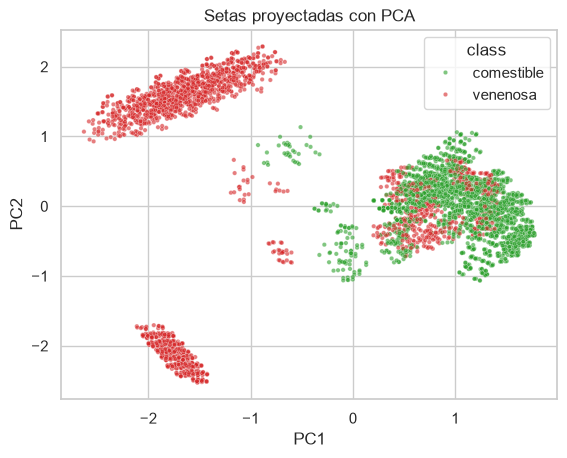

In [3]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_train)  # cada seta pasa a ser un punto (PC1, PC2)
print("Varianza explicada por PC1 y PC2:", pca.explained_variance_ratio_.round(3),
      "-> total", pca.explained_variance_ratio_.sum().round(3))

# Coloreamos con la etiqueta SOLO para mirar: PCA no la ha usado
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train.map({0: "comestible", 1: "venenosa"}),
                hue_order=["comestible", "venenosa"], palette={"comestible": "tab:green", "venenosa": "tab:red"},
                s=10, alpha=0.6)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Setas proyectadas con PCA")
plt.show()

In [4]:
# ¿Qué hay DENTRO de PC1? Sus pesos: cuánto aporta cada una de las 115 columnas
pesos_pc1 = pd.Series(pca.components_[0], index=X_train.columns)
print("Columnas que participan en PC1:", (pesos_pc1 != 0).sum(), "de", X_train.shape[1])
pesos_pc1.reindex(pesos_pc1.abs().sort_values(ascending=False).index).head(5).round(2)

Columnas que participan en PC1: 115 de 115


ring-type_p                   0.29
bruises_t                     0.27
bruises_f                    -0.27
stalk-surface-above-ring_k   -0.26
stalk-surface-below-ring_k   -0.25
dtype: float64

In [5]:
# 📖 Idea del primer libro: ¿cuántas componentes guardan el 95 % de la varianza en NUESTRAS setas?
pca95 = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(X_train)  # un número entre 0 y 1 = % de varianza
print(f"Para guardar el 95 % de la varianza hacen falta {pca95.n_components_} de {X_train.shape[1]} columnas")

Para guardar el 95 % de la varianza hacen falta 40 de 115 columnas


Con solo 2 componentes ya se ven **zonas bastante separadas**: hay estructura que el clustering podrá encontrar.

### Línea base supervisada: Random Forest

**Por qué aquí, si el taller es no supervisado:** es una **regla para medir**. Usamos la etiqueta *solo* para saber **cuánta información hay en los datos**.

- Si un modelo **con** etiqueta acierta casi siempre → las columnas **sí** separan comestibles de venenosas → el clustering tiene algo que encontrar.
- **Random Forest** = muchos árboles de decisión que **votan**; se entrena con `train` y se examina con `test` (datos que no ha visto).

> 📖 **En los libros**
>
> - **Primer libro:** un `DummyClassifier` que responde siempre *«no es un 5»* acierta **más del 90 %** en MNIST, solo porque los 5 son ~10 %. Por eso hace falta una **línea base tonta**: un 90 % puede no significar nada.
> - **Segundo libro:** *«predecir leucemia solo si el bebé se llama Luke»* acierta >98 %… porque la enfermedad es rara. **La precisión sola engaña.**
> - Ambos: un Random Forest son **árboles entrenados con muestras distintas que votan**.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)  # 100 árboles que votan
rf.fit(X_train, y_train)                    # aprende con train
acc = accuracy_score(y_test, rf.predict(X_test))  # examen con test (datos que no ha visto)
print(f"Accuracy con las {X_train.shape[1]} columnas: {acc:.3f}")

Accuracy con las 115 columnas: 1.000


In [7]:
# 📖 Idea de los libros: comparar con un modelo 'tonto' que siempre dice la clase más frecuente
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Modelo tonto: {accuracy_score(y_test, dummy.predict(X_test)):.3f}  vs  Random Forest: {acc:.3f}")

Modelo tonto: 0.514  vs  Random Forest: 1.000


### ¿Cuántas componentes PCA bastan?

Probamos a reducir a *n* componentes y volvemos a entrenar el Random Forest. Buscamos el **mínimo *n*** que mantiene la precisión.

> 📖 **En el primer libro** se hace lo mismo con MNIST: un `Pipeline` de **PCA + Random Forest** busca el mejor nº de componentes y pasa de **784 a ~57** sin perder precisión. Es el equilibrio **velocidad ↔ precisión**: si quitas demasiadas, el modelo pierde información.

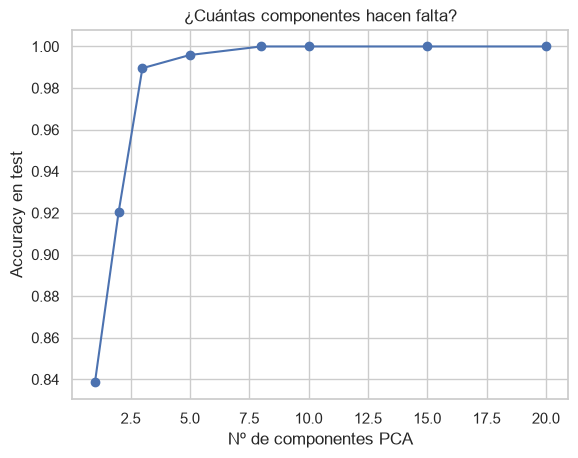

{1: 0.838, 2: 0.921, 3: 0.99, 5: 0.996, 8: 1.0, 10: 1.0, 15: 1.0, 20: 1.0}

In [8]:
n_features = [1, 2, 3, 5, 8, 10, 15, 20]  # valores de n a probar
scores = []

for n in n_features:
    pca_n = PCA(n_components=n, random_state=RANDOM_STATE).fit(X_train)  # PCA aprende SOLO con train
    rf_n = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
    rf_n.fit(pca_n.transform(X_train), y_train)
    scores.append(accuracy_score(y_test, rf_n.predict(pca_n.transform(X_test))))

plt.plot(n_features, scores, marker="o")
plt.xlabel("Nº de componentes PCA"); plt.ylabel("Accuracy en test")
plt.title("¿Cuántas componentes hacen falta?")
plt.show()
dict(zip(n_features, [round(s, 3) for s in scores]))

### t-SNE: reducción **no lineal** para visualizar

**Qué es:** *t-Distributed Stochastic Neighbor Embedding* — coloca cada dato en un mapa 2D para que **los vecinos sigan siendo vecinos**.

- *Imagina una fiesta:* t-SNE acomoda a los invitados en un salón para que **los amigos queden juntos**.
- **PCA** conserva la forma general y sus ejes se interpretan; **t-SNE** conserva los vecinos cercanos, pero sus **ejes y distancias entre grupos no significan nada**.
- ⚠️ **Solo sirve para mirar**, no para sacar conclusiones exactas (y no sabe colocar datos nuevos). Es lento: usamos una muestra.

![t-SNE](assets/taller/f03-tsne.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> 📖 **En el primer libro**
>
> - t-SNE es **casi solo para visualizar**: *no* se usa como paso previo para entrenar un modelo.
> - Ejemplo: 5.000 dígitos de **MNIST** (784 píxeles) en 2D → **10 nubes separadas**, una por dígito, sin decirle cuál es cuál. Igual que nuestras setas.
> - Con el *rollo suizo* (la espiral 3D): **Isomap** lo desenrolla, pero **t-SNE lo rompe en trozos**: exagera los grupos locales y pierde la forma global.

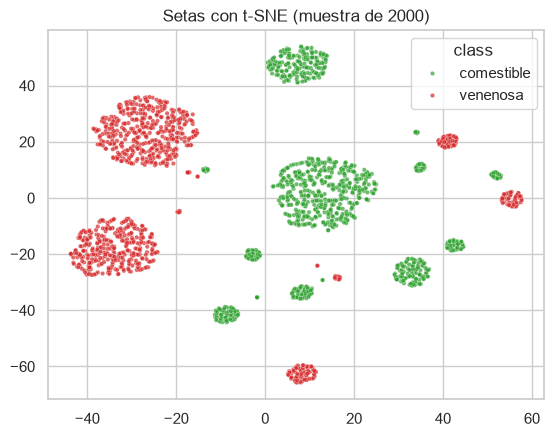

In [9]:
from sklearn.manifold import TSNE

muestra = X_train.sample(2000, random_state=RANDOM_STATE)  # t-SNE es lento: 2000 setas bastan
X_tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE).fit_transform(muestra)

sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1],
                hue=y_train.loc[muestra.index].map({0: "comestible", 1: "venenosa"}), hue_order=["comestible", "venenosa"], palette={"comestible": "tab:green", "venenosa": "tab:red"},
                s=10, alpha=0.7)
plt.title("Setas con t-SNE (muestra de 2000)")
plt.show()

### PCA o t-SNE: ¿cuál uso?

**PCA** para **reducir columnas**; **t-SNE** para **explorar grupos**. Se pueden usar juntos: primero PCA para quitar ruido y luego t-SNE para dibujar.

![PCA o t-SNE](assets/taller/f03-pca-vs-tsne.png)

*Fuente: diapositivas del bootcamp «Aprendizaje No Supervisado» (FactoriaF5).*

> **Resumen fase 03:** con **PCA** se ven zonas separadas; **Random Forest** acierta ≈ 100 % (los datos tienen mucha información) y **~10 componentes PCA** bastan para mantenerlo. **t-SNE** muestra grupos más compactos, pero solo sirve para visualizar.